In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2


In [4]:
guide = pd.read_csv("office_price_guide.csv")
purchases = pd.read_csv("purchases.csv")

print("purchases:", purchases.shape)
purchases.head()

purchases: (577, 14)


,Receipt_id,Date,Pilot_no,City,Shop_type,Product,Quantity,Total_paid_eur,Payment,Shop_rating,Flight_km,Flight_min,Temperature_c,Luggage_kg
0,ES25-00001,2025-12-01,8,Valencia,Souvenir shop,Paella,2.0,296.30,Bizum,3.5,336,54,9.1,17.0
1,ES25-00002,2025-12-01,9,Madrid,Supermarket,Churros,11.0,264.00,Cash,4.5,778,99,3.4,15.8
2,ES25-00003,2025-12-01,11,Salamanca,Specialty store,Jamon,4.1,45.92,Cash,3.0,421,53,6.6,14.6
3,ES25-00004,2025-12-01,9,Salamanca,Market stall,Jamon,4.2,47.46,Card,3.9,517,76,6.8,18.1
4,ES25-00005,2025-12-01,9,Salamanca,Market stall,Jamon,5.7,1225.79,Card,4.1,517,76,6.8,18.8


In [5]:
guide

,List_no,Product,Unit,Fair_min_eur,Fair_max_eur,Home_city
0,1,Jamon,kg,35.0,80.0,Salamanca
1,2,Churros,dozen,3.0,7.0,Madrid
2,3,Turron,bar,6.0,15.0,Alicante
3,4,Paella,kit,20.0,45.0,Valencia
4,5,Saffron,g,5.0,12.0,Albacete
5,6,Barquillos,box,4.0,10.0,Madrid


In [6]:
df = purchases.merge(guide, on="Product", suffixes=("", "_g"))
assert (df["Quantity"] > 0).all(), "zero/negative quantity found!"
df["ppu"] = df["Total_paid_eur"] / df["Quantity"]

df[["Receipt_id", "Date", "Pilot_no", "City", "Product",
    "Quantity", "Total_paid_eur", "ppu"]].head(10)

,Receipt_id,Date,Pilot_no,City,Product,Quantity,Total_paid_eur,ppu
0,ES25-00001,2025-12-01,8,Valencia,Paella,2.0,296.30,148.150000
1,ES25-00002,2025-12-01,9,Madrid,Churros,11.0,264.00,24.000000
2,ES25-00003,2025-12-01,11,Salamanca,Jamon,4.1,45.92,11.200000
3,ES25-00004,2025-12-01,9,Salamanca,Jamon,4.2,47.46,11.300000
4,ES25-00005,2025-12-01,9,Salamanca,Jamon,5.7,1225.79,215.050877
5,ES25-00006,2025-12-01,9,Salamanca,Jamon,3.4,58.99,17.350000
6,ES25-00007,2025-12-01,8,Valencia,Paella,6.0,588.90,98.150000
7,ES25-00008,2025-12-01,9,Salamanca,Jamon,4.3,47.30,11.000000
8,ES25-00009,2025-12-01,8,Valencia,Paella,6.0,459.60,76.600000
9,ES25-00010,2025-12-01,8,Valencia,Paella,4.0,552.40,138.100000


In [7]:
df["fair_price"] = df["ppu"].between(df["Fair_min_eur"], df["Fair_max_eur"],
                                     inclusive="both")
print("fair-priced receipts:", df["fair_price"].sum(), "of", len(df))


fair_home = df[df["fair_price"] & (df["City"] == df["Home_city"])]
print("fair AND in home city:", len(fair_home))

fair-priced receipts: 77 of 577
fair AND in home city: 77


In [8]:
summary = (df.groupby("Product")["ppu"]
             .agg(["min", "max", "count"])
             .join(guide.set_index("Product")[["Fair_min_eur", "Fair_max_eur"]]))
summary.round(2)

,min,max,count,Fair_min_eur,Fair_max_eur
Product,,,,,
Barquillos,0.80,34.10,88,4.0,10.0
Churros,0.60,24.00,99,3.0,7.0
Jamon,7.80,273.20,103,35.0,80.0
Paella,4.05,157.35,96,20.0,45.0
Saffron,1.05,41.10,99,5.0,12.0
Turron,1.20,52.05,92,6.0,15.0


In [9]:
per_pair = df.groupby(["Pilot_no", "Product"])["fair_price"].agg(["any", "all"])
print("pilot×product pairs with ≥1 fair receipt:   ", per_pair["any"].sum())
print("pilot×product pairs where ALL were fair:    ", per_pair["all"].sum())
print("pairs bought more than once:                ", (per_pair["any"] & ~per_pair["all"]).sum() + 0)

pilot×product pairs with ≥1 fair receipt:    57
pilot×product pairs where ALL were fair:     0
pairs bought more than once:                 57


In [10]:
#board builder
board = (fair_home.groupby(["List_no", "Pilot_no"]).size()
           .unstack(fill_value=0)
           .reindex(index=range(1, 7), columns=range(1, 22), fill_value=0)
           > 0).astype(int)

print("board shape:", board.shape, "  (must be (6, 21))")
board

board shape: (6, 21)   (must be (6, 21))


Pilot_no,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
List_no,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,1,1,0,0,0,0,...,0,1,1,1,0,0,0,1,1,1
2,0,0,0,0,1,0,1,0,0,0,...,0,1,0,0,0,1,0,1,0,1
3,1,1,1,0,1,0,1,0,1,0,...,0,1,0,0,0,0,0,1,0,1
4,1,0,0,0,1,1,0,0,1,0,...,0,1,0,0,0,1,0,1,0,1
5,1,0,0,0,1,0,1,0,1,0,...,0,1,0,0,0,1,0,1,0,1
6,1,1,1,0,1,0,1,0,1,1,...,0,1,1,1,0,1,0,1,1,1


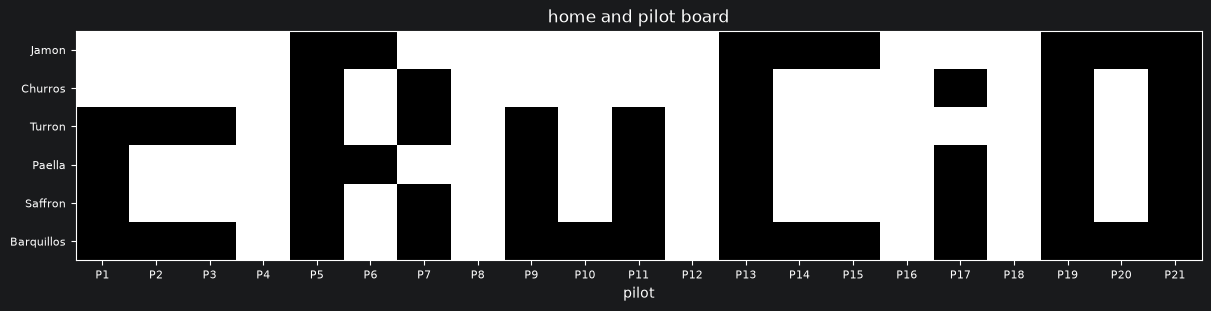

In [15]:
#board render

product_names = guide.set_index("List_no").loc[board.index, "Product"]

fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.imshow(board.values, cmap="binary", aspect="auto")
ax.set_xticks(range(board.shape[1]), [f"P{n}" for n in board.columns], fontsize=8)
ax.set_yticks(range(board.shape[0]), product_names, fontsize=8)
ax.set_xlabel("pilot")
ax.set_title("home and pilot board")
plt.show()